# Maestría en Inteligencia Artificial Aplicada
## TC5061.10 · Operaciones de Aprendizaje Automático
### Proyecto MiBici · Equipo 29 · Pregunta 3: *clustering* de estaciones

- **Notebook:** "1.0-fbr-p3-exploracion-clustering.ipynb"
- **Autor:** Félix Beltrán (A00532697)
- **Entrega:** Construye · Proyecto MiBici: propuesta y base reproducible (entrega 1)
- **Pregunta (P3):** *¿Qué grupos de estaciones comparten patrones de uso y dónde se ubican en la ciudad?*
- **Usuario del resultado:** Planeación urbana y expansión del sistema

**Alcance.** Este notebook explora P3 y deja la evidencia de la propuesta para esta pregunta. Lee los CSV crudos con la limpieza mínima que exige el análisis; la ingesta oficial, el EDA general y la limpieza completa están a cargo de otros integrantes. La lógica final se trasladará al módulo "mibici" (sección 11).


---
## 1. Formulación del problema (Paso 1)

Ver "ML Canvas" en reporte

---
## 2. Configuración

Para este notebook, los datos crudos se leen directamente de la carpeta "DatosMiBici", que está junto al repositorio ("D:\REPOS_MAESTRIA\DatosMiBici"). Ahí deben estar los CSV mensuales y la nomenclatura de estaciones.

In [93]:
# Librerías estándar
import hashlib
import json
import os
import subprocess
import sys
import tempfile
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de tqdm en Jupyter, sin efecto
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")             # silencia un aviso informativo de MLflow

# Librerías de análisis
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

# Raíz del proyecto: este notebook vive en notebooks/
PROJ_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJ_ROOT))

# Rutas centralizadas del proyecto (objeto CONFIG de mibici/config.py). Se silencia el log de config para no imprimir rutas locales.
from loguru import logger
logger.disable("mibici")
from mibici.config import CONFIG

RAW_DATA_DIR = CONFIG.raw_data_dir
INTERIM_DATA_DIR = CONFIG.interim_data_dir
FIGURES_DIR = CONFIG.reports_dir / "figures"

# Los CSV crudos se leen directamente de la carpeta DatosMiBici, hermana del repositorio
RAW_DIR = PROJ_ROOT.parent / "DatosMiBici"
assert any(RAW_DIR.glob("datos_abiertos_*.csv")), f"No hay CSV de MiBici en {RAW_DIR}"

CACHE_DIR = INTERIM_DATA_DIR / "p3_flujos_horarios"   # data/ está ignorado por Git
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Carpeta de datos crudos:", RAW_DIR.name)

Carpeta de datos crudos: DatosMiBici


In [94]:
# ---------------- Parámetros de P3 ----------------
SEED = 42
MESES = pd.period_range("2025-01", "2026-09", freq="M")       # meses que se leen
AJUSTE = ("2025-01-01", "2026-04-30")      # periodo de entrenamiento: red estable (antes de las aperturas)
EVALUACION = ("2026-05-01", "2026-09-30")  # periodo de evaluación: incluye la expansión de la red
DURACION_MIN_SEG = 60      # viajes de menos de 1 minuto se descartan (sección 3.3)
MIN_DIAS_ACTIVOS = 60      # días con viajes que necesita una estación para tener perfil confiable (sección 4.6)
FRANJAS = {                # franjas de día hábil, definidas con la curva horaria (sección 4.2)
    "am": [6, 7, 8, 9],
    "mid": [11, 12, 13, 14, 15],
    "pm": [17, 18, 19, 20],
    "night": [21, 22, 23, 0, 1, 2, 3, 4, 5],
}
K_BASELINE = 5             # número de grupos del baseline (fijo, sin optimizar)
K_COMPARACION = [4, 5, 6]  # corridas extra para la captura de comparación en MLflow
LAT_REF = 20.67            # latitud de referencia de Guadalajara para proyectar a km
CENTRO_GDL = (20.6767, -103.3469)  # Catedral de Guadalajara: referencia para medir distancia al centro
EXPERIMENTO = "mibici-equipo29"
EQUIPO = "equipo29"
np.random.seed(SEED)

In [95]:
# Estilo de las gráficas: superficie clara, tinta neutra, rejilla tenue y paleta categórica en orden fijo
SUPERFICIE, TINTA, TINTA2, TENUE, REJILLA, EJE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MARCADORES = ["o", "s", "^", "D", "v", "P", "X", "*"]   # segunda codificación: el grupo no depende solo del color
AZUL_SEQ = ListedColormap(["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIVERGENTE = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ef8f8e", "#a32f2e"])

plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": EJE, "axes.labelcolor": TINTA2, "axes.titlecolor": TINTA,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": TENUE, "ytick.color": TENUE, "axes.grid": True, "grid.color": REJILLA,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 9.5, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def guardar(fig, nombre):
    # Guarda la figura en reports/figures/ (convención de la plantilla) y la muestra
    fig.savefig(FIGURES_DIR / nombre)
    plt.show()

---
## 3. Definición de los datos (Paso 2)


### 3.1 Fuente

- **Viajes mensuales:** "datos_abiertos_AAAA_MM.csv", portal de datos abiertos de MiBici: <https://mibici.net/es/datos-abiertos/>. Un archivo por mes; cada fila es un viaje.
- **Nomenclatura de estaciones:** "nomenclatura_2026_09.csv": <https://mibici.net/site/assets/files/1118/nomenclatura_2026_09.csv>. Trae id, nombre, latitud, longitud y capacidad.
- **Validación externa:** fichas estadísticas del IIEG Jalisco elaboradas con los mismos datos abiertos: <https://iieg.gob.mx/ns/?page_id=25284>.

**Rango de fechas: enero de 2025 a septiembre de 2026 (21 meses).** Con más de un año completo, el perfil promedia la estacionalidad: vacaciones, lluvias y periodos escolares. Además deja cinco meses posteriores para evaluar, que coinciden con la expansión de la red.

No se usan años anteriores porque la red de estaciones y el formato de los archivos cambian, y porque el periodo 2020-2021 está afectado por la pandemia.

In [96]:
# Inventario de archivos: ¿están todos los meses del rango?
esperados = [f"datos_abiertos_{p.year}_{p.month:02d}.csv" for p in MESES]
disponibles = sorted(p.name for p in RAW_DIR.glob("datos_abiertos_*.csv"))
faltantes = [f for f in esperados if f not in disponibles]
tam_mb = sum((RAW_DIR / f).stat().st_size for f in esperados if f not in faltantes) / 1e6
print(f"Meses esperados: {len(esperados)} | disponibles en el rango: {len(esperados) - len(faltantes)} | faltantes: {faltantes or 'ninguno'}")
print(f"Tamaño total de los CSV del rango: {tam_mb:,.0f} MB")
assert not faltantes, "Faltan meses: descárgalos del portal antes de continuar"

Meses esperados: 21 | disponibles en el rango: 21 | faltantes: ninguno
Tamaño total de los CSV del rango: 685 MB


### 3.2 Lectura mínima de los CSV crudos

Solo se aplica la limpieza que P3 necesita:

- Se detecta la codificación de cada archivo (algunos meses vienen en latin-1).
- Se leen solo 5 columnas ("Viaje_Id", "Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"); los datos personales nunca se cargan.
- Se quitan los duplicados exactos, para no contar dos veces un viaje.
- Se descartan las fechas que no se puedan leer y los viajes de menos de 1 minuto, que en su mayoría son anclajes fallidos.

Después, cada mes se resume en salidas y llegadas por estación y hora. Ese resumen se guarda en "data/interim/" y solo se recalcula si cambia el archivo crudo.

In [97]:
COLUMNAS = ["Viaje_Id", "Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"]
FORMATO_FECHA = "%Y-%m-%d %H:%M:%S"


def sha256_archivo(ruta, bloque=1 << 20):
    # Huella SHA-256 del archivo crudo: identifica exactamente qué datos se usaron
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


def detectar_codificacion(ruta):
    # Si el archivo completo se decodifica como utf-8, es utf-8; si no, es latin-1
    try:
        ruta.read_bytes().decode("utf-8")
        return "utf-8"
    except UnicodeDecodeError:
        return "latin-1"


def leer_mes(ruta):
    # Lee un CSV mensual SOLO con las columnas que usa P3 y aplica la limpieza mínima.
    # Regresa los viajes válidos y una bitácora con lo que se descartó y por qué.
    cod = detectar_codificacion(ruta)
    v = pd.read_csv(ruta, encoding=cod, usecols=COLUMNAS, na_values=["NULL"],
                    dtype={"Inicio_del_viaje": str, "Fin_del_viaje": str})
    bit = {"archivo": ruta.name, "codificacion": cod, "filas_crudas": len(v)}
    bit["duplicados_exactos"] = int(v.duplicated().sum())
    v = v.drop_duplicates()
    for col in ["Inicio_del_viaje", "Fin_del_viaje"]:
        v[col] = pd.to_datetime(v[col], format=FORMATO_FECHA, errors="coerce")
    malas = v[["Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"]].isna().any(axis=1)
    bit["fechas_o_ids_invalidos"] = int(malas.sum())
    v = v[~malas]
    dur = (v["Fin_del_viaje"] - v["Inicio_del_viaje"]).dt.total_seconds()
    bit["duracion_negativa"] = int((dur < 0).sum())
    bit["duracion_menor_1min"] = int(((dur >= 0) & (dur < DURACION_MIN_SEG)).sum())
    bit["mismo_origen_destino"] = int((v["Origen_Id"] == v["Destino_Id"]).sum())
    bit["duracion_mediana_min"] = round(float(dur.median()) / 60, 2)
    v = v[dur >= DURACION_MIN_SEG]
    bit["viajes_validos"] = len(v)
    return v, bit


def flujos_horarios(v):
    # Resume los viajes de un mes en salidas y llegadas por estación y hora (la hora de llegada es la de fin del viaje)
    sal = v.groupby([v["Origen_Id"].rename("estacion"), v["Inicio_del_viaje"].dt.floor("h").rename("hora")]).size()
    lle = v.groupby([v["Destino_Id"].rename("estacion"), v["Fin_del_viaje"].dt.floor("h").rename("hora")]).size()
    return (pd.concat([sal.rename("salidas"), lle.rename("llegadas")], axis=1)
              .fillna(0).astype("int32").reset_index())


def procesar_mes(ruta):
    # Lee y resume un mes, usando el resumen guardado si el archivo crudo no ha cambiado
    huella = sha256_archivo(ruta)
    f_flujos = CACHE_DIR / f"{ruta.stem}_{huella[:12]}.csv.gz"
    f_bit = CACHE_DIR / f"{ruta.stem}_{huella[:12]}.json"
    if f_flujos.exists() and f_bit.exists():
        return pd.read_csv(f_flujos, parse_dates=["hora"]), json.loads(f_bit.read_text())
    v, bit = leer_mes(ruta)
    fl = flujos_horarios(v)
    bit["sha256"] = huella
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    fl.to_csv(f_flujos, index=False)
    f_bit.write_text(json.dumps(bit))
    return fl, bit

In [98]:
# Procesar los 21 meses (la primera vez tarda unos minutos; después usa el resumen de data/interim)
t0 = time.time()
partes, bitacoras = [], []
for nombre in esperados:
    fl, bit = procesar_mes(RAW_DIR / nombre)
    partes.append(fl)
    bitacoras.append(bit)

# Un viaje que cruza la medianoche de fin de mes aparece en dos archivos: se suman sus flujos
flujos = (pd.concat(partes).groupby(["estacion", "hora"], as_index=False)[["salidas", "llegadas"]].sum())
bitacora = pd.DataFrame(bitacoras)
bitacora.insert(0, "mes", bitacora["archivo"].str.extract(r"(\d{4}_\d{2})")[0])
print(f"Listo en {time.time() - t0:,.0f} s · {len(flujos):,} filas estación-hora · "
      f"{flujos.salidas.sum():,} viajes válidos")

# Nomenclatura de estaciones
f_nom = RAW_DIR / "nomenclatura_2026_09.csv"
nom = pd.read_csv(f_nom, encoding=detectar_codificacion(f_nom)).set_index("id")
nom["municipio"] = nom["name"].str.extract(r"\((GDL|ZPN|TLQ)-")[0].fillna("otro")

# Versión de los datos: huella que combina el sha256 de cada CSV usado (si cambia un archivo, cambia la versión)
huellas = {b["archivo"]: b["sha256"] for b in bitacoras}
huellas[f_nom.name] = sha256_archivo(f_nom)
DATA_VERSION = hashlib.sha256(json.dumps(huellas, sort_keys=True).encode()).hexdigest()[:12]
print("data_version:", DATA_VERSION)

Listo en 11 s · 3,335,642 filas estación-hora · 7,648,039 viajes válidos
data_version: b82961c841c7


### 3.3 Tamaño real obtenido y bitácora de limpieza mínima

In [99]:
cols = ["mes", "codificacion", "filas_crudas", "duplicados_exactos", "fechas_o_ids_invalidos",
        "duracion_negativa", "duracion_menor_1min", "mismo_origen_destino", "duracion_mediana_min", "viajes_validos"]
estaciones_mes = (flujos.assign(mes=flujos.hora.dt.strftime("%Y_%m"))
                  .query("salidas > 0").groupby("mes").estacion.nunique().rename("estaciones_con_salidas"))
tabla_mes = bitacora[cols].merge(estaciones_mes, left_on="mes", right_index=True, how="left")
display(tabla_mes.style.format(thousands=",", precision=2).hide(axis="index"))

tot = bitacora[["filas_crudas", "duplicados_exactos", "duracion_menor_1min", "viajes_validos"]].sum()
est_viajes = set(flujos.estacion)
print(f"Meses: {len(bitacora)} | viajes en los CSV: {tot.filas_crudas:,} | duplicados exactos: {tot.duplicados_exactos:,} | "
      f"< 1 min: {tot.duracion_menor_1min:,} ({tot.duracion_menor_1min / tot.filas_crudas:.1%}) | "
      f"viajes válidos: {tot.viajes_validos:,}")
print(f"Estaciones en la nomenclatura: {len(nom)} | estaciones con viajes: {len(est_viajes)} | "
      f"con viajes y en la nomenclatura: {len(est_viajes & set(nom.index))}")
print("Codificación por archivo:", bitacora.codificacion.value_counts().to_dict())

mes,codificacion,filas_crudas,duplicados_exactos,fechas_o_ids_invalidos,duracion_negativa,duracion_menor_1min,mismo_origen_destino,duracion_mediana_min,viajes_validos,estaciones_con_salidas
2025_01,latin-1,"380,184",0,0,0,"9,282","20,901",9.52,"370,902",368
2025_02,latin-1,"372,529",0,0,0,"9,018","20,286",9.70,"363,511",367
2025_03,utf-8,"405,110",0,0,0,"10,351","22,362",9.63,"394,759",367
2025_04,utf-8,"366,193",0,0,0,"9,137","21,103",9.50,"357,056",367
2025_05,utf-8,"395,891",0,0,0,"10,051","22,287",9.50,"385,840",367
2025_06,utf-8,"356,611",0,0,0,"9,726","20,837",9.58,"346,885",368
2025_07,latin-1,"368,186",0,0,0,"9,773","21,363",9.67,"358,413",367
2025_08,utf-8,"374,727",0,0,0,"10,099","21,619",9.63,"364,628",367
2025_09,utf-8,"376,789",0,0,0,"10,190","21,323",9.62,"366,599",367
2025_10,utf-8,"420,064",0,0,0,"10,524","23,004",9.65,"409,540",368


Meses: 21 | viajes en los CSV: 7,894,097 | duplicados exactos: 758 | < 1 min: 245,300 (3.1%) | viajes válidos: 7,648,039
Estaciones en la nomenclatura: 484 | estaciones con viajes: 472 | con viajes y en la nomenclatura: 470
Codificación por archivo: {'utf-8': 17, 'latin-1': 4}


In [100]:
iieg = pd.DataFrame([
    ("Enero–diciembre 2025", "2025_01", "2025_12", 4_530_330, "IIEG (2026)"),
    ("Enero–junio 2025", "2025_01", "2025_06", 2_275_288, "IIEG (2025)"),
    ("Marzo 2025", "2025_03", "2025_03", 405_039, "IIEG (2025)"),
], columns=["periodo", "desde", "hasta", "viajes_iieg", "fuente"])
filas = bitacora.set_index("mes")["filas_crudas"]
iieg["viajes_csv"] = [filas.loc[a:b].sum() for a, b in zip(iieg.desde, iieg.hasta)]
iieg["diferencia"] = iieg.viajes_csv - iieg.viajes_iieg
iieg["diferencia_%"] = 100 * iieg.diferencia / iieg.viajes_iieg
display(iieg.drop(columns=["desde", "hasta"]).style.format({"viajes_iieg": "{:,}", "viajes_csv": "{:,}",
        "diferencia": "{:+,}", "diferencia_%": "{:+.3f}%"}).hide(axis="index"))

periodo,viajes_iieg,fuente,viajes_csv,diferencia,diferencia_%
Enero–diciembre 2025,"4,530,330",IIEG (2026),"4,532,032","+1,702",+0.038%
Enero–junio 2025,"2,275,288",IIEG (2025),"2,276,518","+1,230",+0.054%
Marzo 2025,"405,039",IIEG (2025),"405,110",+71,+0.018%


### 3.4 Variables originales que usa P3

- **De los viajes:** inicio y fin del viaje (hora, día y duración), estación de origen y de destino, y el id del viaje (solo para detectar duplicados).
- **De la nomenclatura:** ubicación de cada estación (para el baseline y el mapa), nombre (municipio) y capacidad (para describir los grupos).

### 3.5 Estaciones, expansión de la red y partición temporal

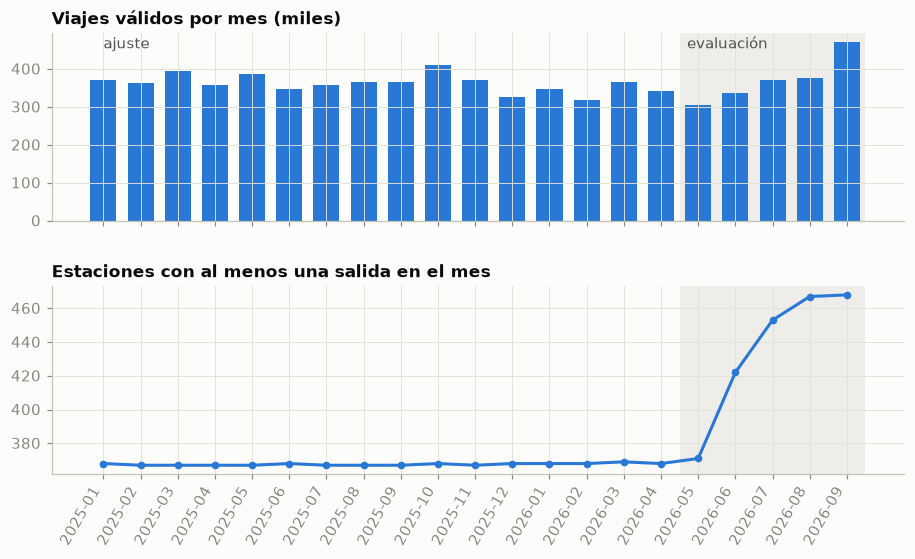

Mes de la primera salida de cada estación (solo meses con aperturas):
min
2025-01    368
2025-06      1
2025-10      1
2025-12      1
2026-05     12
2026-06     45
2026-07     27
2026-08     15
Freq: M

Estaciones nuevas (primera salida en mayo 2026 o después): 99 · por municipio: {'GDL': 71, 'ZPN': 28}
Estaciones sin ninguna salida en el rango: 14
Ids con viajes que no están en la nomenclatura: [405, 407] (1,887 salidas; quedan fuera porque no tienen ubicación)


In [101]:
# Primer y último mes con viajes de cada estación (en la nomenclatura)
act = flujos.assign(mes=flujos.hora.dt.to_period("M")).groupby("estacion").mes.agg(["min", "max"])
act = act[act.index.isin(nom.index)]
aperturas = act["min"].value_counts().sort_index()
viajes_mes = bitacora.set_index("mes")["viajes_validos"]
est_mes = tabla_mes.set_index("mes")["estaciones_con_salidas"]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, gridspec_kw={"hspace": 0.35})
x = np.arange(len(viajes_mes))
corte = list(viajes_mes.index).index("2026_05") - 0.5
for ax in (a1, a2):
    ax.axvspan(corte, len(x) - 0.5, color=REJILLA, alpha=0.5, lw=0)
a1.bar(x, viajes_mes.values / 1e3, color=SERIES[0], width=0.7)
a1.set_title("Viajes válidos por mes (miles)")
a1.text(corte + 0.2, a1.get_ylim()[1] * 0.92, "evaluación", color=TINTA2)
a1.text(0, a1.get_ylim()[1] * 0.92, "entrenamiento", color=TINTA2)
a2.plot(x, est_mes.values, color=SERIES[0], marker="o", ms=4)
a2.set_title("Estaciones con al menos una salida en el mes")
a2.set_xticks(x, [m.replace("_", "-") for m in viajes_mes.index], rotation=60, ha="right")
guardar(fig, "p3_viajes_y_estaciones_por_mes.png")

print("Mes de la primera salida de cada estación (solo meses con aperturas):")
print(aperturas.to_string())
nuevas = act.index[act["min"] >= pd.Period("2026-05", "M")]
print(f"\nEstaciones nuevas (primera salida en mayo 2026 o después): {len(nuevas)} · "
      f"por municipio: {nom.loc[nuevas, 'municipio'].value_counts().to_dict()}")
print("Estaciones sin ninguna salida en el rango:", len(set(nom.index) - set(act.index)))
fuera = sorted(set(flujos.estacion) - set(nom.index))
print("Ids con viajes que no están en la nomenclatura:", fuera,
      f"({flujos[flujos.estacion.isin(fuera)].salidas.sum():,} salidas; quedan fuera porque no tienen ubicación)")

**Partición temporal.** Las aperturas de estaciones empiezan en mayo de 2026, y de ahí sale el corte:

- **Entrenamiento (train):** enero 2025 a abril 2026, 16 meses con la red estable. Entrenamiento del modelo para encontrar las variables.
- **Evaluación (test):** mayo a septiembre 2026, 5 meses. Verificamos las variables para ver si los grupos se sostienen y se asignan las estaciones nuevas.

**Cómo se evita usar información del futuro.** Todo lo que el modelo aprende sale solo del periodo de entrenamiento. Los meses de evaluación se procesan aparte, y las estaciones nuevas solo se asignan al grupo al que más se parecen.


In [102]:
# Comprobación: ninguna columna con datos personales llegó a memoria
personales = {"Usuario_Id", "Genero", "Año_de_nacimiento", "A�o_de_nacimiento"}
assert personales.isdisjoint(COLUMNAS) and personales.isdisjoint(flujos.columns)
print("Columnas leídas de los viajes:", COLUMNAS)
print("Columnas de la tabla de trabajo:", list(flujos.columns))

Columnas leídas de los viajes: ['Viaje_Id', 'Inicio_del_viaje', 'Fin_del_viaje', 'Origen_Id', 'Destino_Id']
Columnas de la tabla de trabajo: ['estacion', 'hora', 'salidas', 'llegadas']


---
## 4. De los viajes a las variables: evidencia (Paso 3)

*"Indiquen qué variables construirán y por qué son pertinentes."*

Lo que se solicita para P3 es identificar grupos en base a **patrones de uso**. Vamos a explorar cómo se usan las estaciones y de ahí salen las variables.

Para que una estación chica y una grande con el mismo patrón queden juntas, casi todas las variables son **proporciones**: describen la *forma* del uso, no el tamaño. El tamaño entra en una sola variable, en escala logarítmica.

In [103]:
def filtrar_periodo(fl, inicio, fin):
    # Flujos horarios dentro de [inicio, fin] (fechas incluidas)
    return fl[(fl.hora >= pd.Timestamp(inicio)) & (fl.hora < pd.Timestamp(fin) + pd.Timedelta(days=1))]


def matrices_horarias(fl):
    # Salidas y llegadas de DÍA HÁBIL por estación (filas) y hora del día (columnas 0 a 23)
    hab = fl[fl.hora.dt.dayofweek < 5].assign(h=lambda d: d.hora.dt.hour)
    piv = lambda col: hab.pivot_table(index="estacion", columns="h", values=col, aggfunc="sum",
                                      fill_value=0).reindex(columns=range(24), fill_value=0)
    return piv("salidas"), piv("llegadas")


def perfil_estaciones(fl, franjas=FRANJAS):
    # Variables CANDIDATAS de uso por estación, calculadas solo con los flujos fl de un periodo
    fl = fl.assign(fecha=fl.hora.dt.normalize(), finde=fl.hora.dt.dayofweek >= 5)
    g = fl.groupby("estacion")
    p = pd.DataFrame({"dias_activos": g.fecha.nunique(), "salidas": g.salidas.sum(), "llegadas": g.llegadas.sum()})
    p["trips_day"] = (p.salidas + p.llegadas) / 2 / p.dias_activos            # viajes por día activo
    p["log_trips_day"] = np.log1p(p.trips_day)
    p["weekend_share"] = fl[fl.finde].groupby("estacion").salidas.sum().reindex(p.index, fill_value=0) / p.salidas
    sal, lle = (m.reindex(p.index, fill_value=0) for m in matrices_horarias(fl))
    p["salidas_habiles"] = sal.sum(axis=1)
    for nombre, horas in franjas.items():                                      # forma del día hábil
        p[f"dep_{nombre}"] = sal[horas].sum(axis=1) / sal.sum(axis=1)
        p[f"arr_{nombre}"] = lle[horas].sum(axis=1) / lle.sum(axis=1)
    for nombre in ["am", "pm"]:                                                # balance en hora pico
        s, l = sal[franjas[nombre]].sum(axis=1), lle[franjas[nombre]].sum(axis=1)
        p[f"net_{nombre}"] = (l - s) / (l + s)
    return p.replace([np.inf, -np.inf], np.nan)


CANDIDATAS = ["log_trips_day", "weekend_share", "dep_am", "dep_mid", "dep_pm", "dep_night",
              "net_am", "net_pm", "arr_am", "arr_mid", "arr_pm", "arr_night"]


def elegibles(p):
    # Estaciones con ubicación conocida y suficientes días con viajes para que su perfil sea confiable
    ok = p.index.isin(nom.index) & (p.dias_activos >= MIN_DIAS_ACTIVOS)
    return p[ok].dropna(subset=CANDIDATAS)


fl_aj, fl_ev = filtrar_periodo(flujos, *AJUSTE), filtrar_periodo(flujos, *EVALUACION)
perf_aj, perf_ev = perfil_estaciones(fl_aj), perfil_estaciones(fl_ev)
aj, ev = elegibles(perf_aj), elegibles(perf_ev)
print(f"Entrenamiento: {len(perf_aj)} estaciones con viajes → {len(aj)} elegibles | "
      f"Evaluación: {len(perf_ev)} → {len(ev)} elegibles (mínimo {MIN_DIAS_ACTIVOS} días activos)")

Ajuste: 371 estaciones con viajes → 370 elegibles | Evaluación: 471 → 453 elegibles (mínimo 60 días activos)


### 4.1 Intensidad de uso → "log_trips_day"

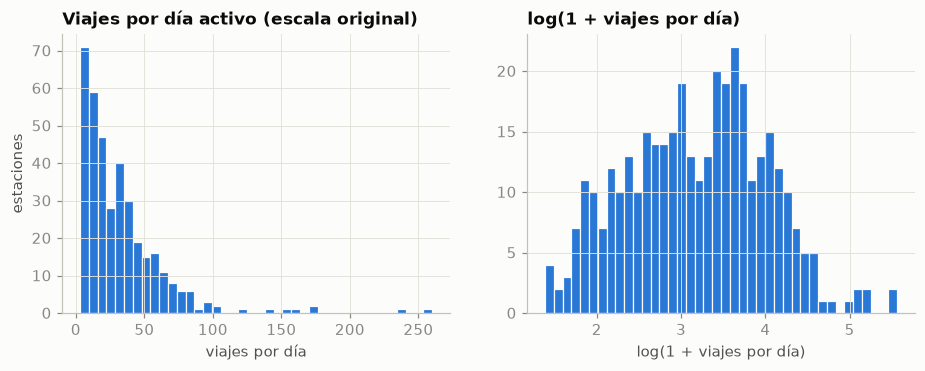

Asimetría: original 3.06 → log 0.02 | rango: 3.0 a 260.1 viajes/día (la mayor usa 11 veces la mediana)


In [104]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.3))
a1.hist(aj.trips_day, bins=40, color=SERIES[0], edgecolor=SUPERFICIE, linewidth=0.8)
a1.set_title("Viajes por día activo (escala original)")
a1.set_xlabel("viajes por día"); a1.set_ylabel("estaciones")
a2.hist(aj.log_trips_day, bins=40, color=SERIES[0], edgecolor=SUPERFICIE, linewidth=0.8)
a2.set_title("log(1 + viajes por día)")
a2.set_xlabel("log(1 + viajes por día)")
guardar(fig, "p3_intensidad_uso.png")
print(f"Asimetría: original {aj.trips_day.skew():.2f} → log {aj.log_trips_day.skew():.2f} | "
      f"rango: {aj.trips_day.min():.1f} a {aj.trips_day.max():.1f} viajes/día "
      f"(la mayor usa {aj.trips_day.max() / aj.trips_day.median():.0f} veces la mediana)")

La intensidad está muy sesgada: pocas estaciones concentran mucho uso. Sin el logaritmo, esas pocas estaciones dominarían las distancias del *clustering*. Con el logaritmo, la distribución queda casi simétrica y la intensidad cuenta como una variable más.

### 4.2 Curva horaria del sistema → franjas y "weekend_share"

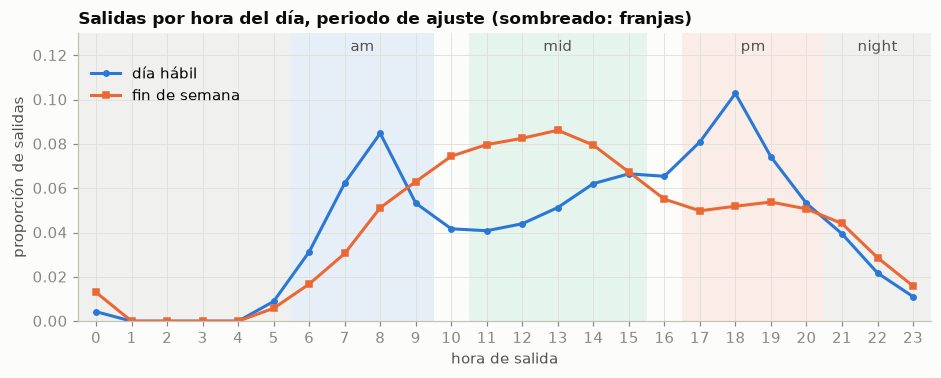

Horas con más salidas en día hábil: [8, 17, 18, 19]
Proporción de salidas en fin de semana (sistema): 0.208 (si fuera uniforme sería 2/7 = 0.286)


In [105]:
fl_aj_h = fl_aj.assign(h=fl_aj.hora.dt.hour, finde=fl_aj.hora.dt.dayofweek >= 5)
curva = fl_aj_h.groupby(["finde", "h"]).salidas.sum().unstack(0)
curva = curva / curva.sum()                      # proporción de las salidas de cada tipo de día por hora
fig, ax = plt.subplots(figsize=(10, 3.4))
colores_franja = {"am": SERIES[0], "mid": SERIES[2], "pm": SERIES[1], "night": TENUE}
for nombre, horas in FRANJAS.items():
    for h in horas:
        ax.axvspan(h - 0.5, h + 0.5, color=colores_franja[nombre], alpha=0.10, lw=0)
    ax.text(np.mean(horas) if nombre != "night" else 22, 0.122, nombre, ha="center", color=TINTA2)
ax.plot(curva.index, curva[False], color=SERIES[0], marker="o", ms=3.5, label="día hábil")
ax.plot(curva.index, curva[True], color=SERIES[1], marker="s", ms=3.5, label="fin de semana")
ax.set_xticks(range(24)); ax.set_xlim(-0.5, 23.5); ax.set_ylim(0, 0.13)
ax.set_xlabel("hora de salida"); ax.set_ylabel("proporción de salidas")
ax.set_title("Salidas por hora del día, periodo de entrenamiento (sombreado: franjas)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.93))
guardar(fig, "p3_curva_horaria_sistema.png")
picos = curva[False].sort_values(ascending=False).head(4).index.tolist()
print("Horas con más salidas en día hábil:", sorted(picos))
print(f"Proporción de salidas en fin de semana (sistema): {fl_aj_h[fl_aj_h.finde].salidas.sum() / fl_aj_h.salidas.sum():.3f} "
      f"(si fuera uniforme sería 2/7 = {2/7:.3f})")

El día hábil tiene tres momentos claros: **pico de mañana** (am), **actividad de mediodía** (mid) y **pico de tarde** (pm). La noche (night) tiene poco uso, pero distingue a las zonas de vida nocturna. Las franjas se definen con estos picos. El fin de semana tiene otra forma, más plana y centrada en el mediodía (menos personas que trabajan las usan como transporte de trabajo), y pesa menos de lo que le tocaría por número de días. Por eso "weekend_share" separa las estaciones de traslado de las recreativas.

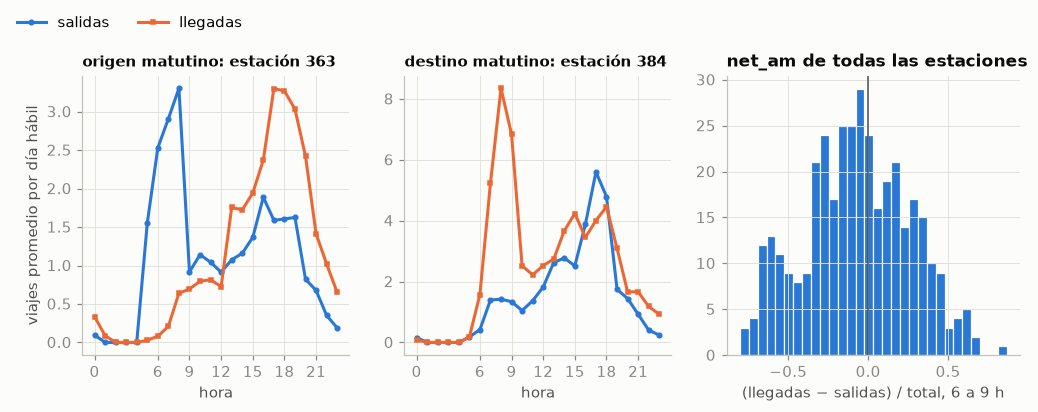

origen matutino    363: (GDL-229)C. Guanajuato / C. Miguel Galindo | net_am=-0.71, net_pm=+0.36
destino matutino   384: (GDL-252) C. Calpulalpan / C. Independencia | net_am=+0.66, net_pm=-0.01
Estaciones con net_am < -0.3 (se vacían en la mañana): 91 | con net_am > 0.3 (se llenan en la mañana): 51


In [106]:
grandes = aj[aj.trips_day >= aj.trips_day.median()]
ejemplos = {"origen matutino": grandes.net_am.idxmin(), "destino matutino": grandes.net_am.idxmax()}
dias_habiles = fl_aj.hora.dt.normalize()[fl_aj.hora.dt.dayofweek < 5].nunique()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, (tipo, est) in zip(axes[:2], ejemplos.items()):
    ax.plot(range(24), sal_h.loc[est] / dias_habiles, color=SERIES[0], marker="o", ms=3, label="salidas")
    ax.plot(range(24), lle_h.loc[est] / dias_habiles, color=SERIES[1], marker="s", ms=3, label="llegadas")
    ax.set_title(f"{tipo}: estación {est}", fontsize=10)
    ax.set_xlabel("hora"); ax.set_xticks([0, 6, 9, 12, 15, 18, 21])
axes[0].set_ylabel("viajes promedio por día hábil")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.06, 1.08), ncol=2)
axes[2].hist(aj.net_am, bins=30, color=SERIES[0], edgecolor=SUPERFICIE, linewidth=0.8)
axes[2].axvline(0, color=TINTA2, lw=1)
axes[2].set_title("net_am de todas las estaciones"); axes[2].set_xlabel("(llegadas − salidas) / total, 6 a 9 h")
guardar(fig, "p3_flujo_neto_ejemplos.png")
for tipo, est in ejemplos.items():
    print(f"{tipo:17s} {est:>4}: {nom.loc[est, 'name']} | net_am={aj.loc[est, 'net_am']:+.2f}, net_pm={aj.loc[est, 'net_pm']:+.2f}")
print(f"Estaciones con net_am < -0.3 (se vacían en la mañana): {(aj.net_am < -0.3).sum()} | "
      f"con net_am > 0.3 (se llenan en la mañana): {(aj.net_am > 0.3).sum()}")

Una estación de **origen matutino** pierde bicicletas en la mañana y las recupera en la tarde. Una de **destino matutino** hace lo contrario. "net_am" y "net_pm" resumen ese balance en un número entre −1 (solo salen) y +1 (solo llegan).

### 4.3 Redundancia: de 12 candidatas a las variables finales

Vamos a revisar si hay variables muy correlacionadas para eliminar las que "digan lo mismo"

descartada,VIF,R² explicado por las demás
arr_mid,7.3,0.863
arr_pm,10.5,0.905
arr_am,17.6,0.943
dep_mid,11.0,0.909
dep_am,5.1,0.804


Variables finales: ['log_trips_day', 'weekend_share', 'net_am', 'net_pm', 'dep_pm', 'dep_night', 'arr_night']
VIF final: {'log_trips_day': 1.25, 'weekend_share': 1.15, 'net_am': 2.33, 'net_pm': 2.42, 'dep_pm': 2.21, 'dep_night': 1.11, 'arr_night': 1.74}


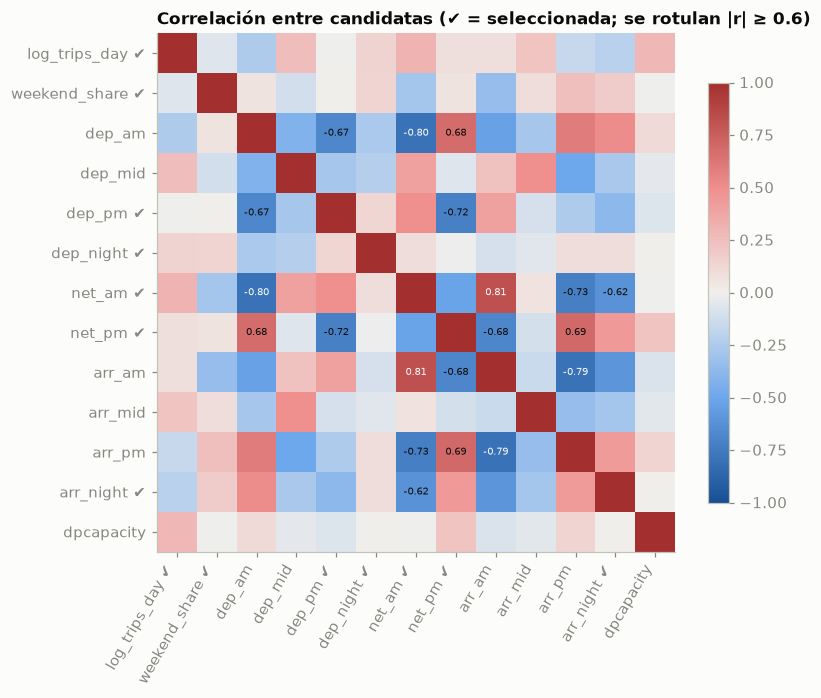

Capacidad (dpcapacity): |r| máxima con las candidatas = 0.29. No se usa como variable de uso (es infraestructura); solo sirve para describir los grupos.


In [107]:
PRIORIDAD = ["log_trips_day", "weekend_share", "net_am", "net_pm", "dep_am", "dep_pm",
             "dep_mid", "dep_night", "arr_am", "arr_pm", "arr_mid", "arr_night"]
UMBRAL_VIF = 5


def vif(df):
    # VIF de cada columna: 1 / (1 - R²) de la regresión de esa columna contra las demás
    from sklearn.linear_model import LinearRegression
    r2 = {c: LinearRegression().fit(df.drop(columns=c), df[c]).score(df.drop(columns=c), df[c]) for c in df}
    return pd.Series({c: 1 / (1 - r) for c, r in r2.items()})


seleccion, pasos = list(PRIORIDAD), []
while (v := vif(aj[seleccion])).max() >= UMBRAL_VIF:
    fuera = [c for c in seleccion if v[c] >= UMBRAL_VIF][-1]       # la de menor prioridad entre las redundantes
    pasos.append({"descartada": fuera, "VIF": v[fuera], "R² explicado por las demás": 1 - 1 / v[fuera]})
    seleccion.remove(fuera)
display(pd.DataFrame(pasos).style.format({"VIF": "{:.1f}", "R² explicado por las demás": "{:.3f}"}).hide(axis="index"))
print("Variables finales:", seleccion)
print("VIF final:", vif(aj[seleccion]).round(2).to_dict())

# Evidencia visual: correlación entre todas las candidatas (y la capacidad, como referencia)
corr = aj[CANDIDATAS].join(nom["dpcapacity"]).corr()
fig, ax = plt.subplots(figsize=(7.6, 6.2))
im = ax.imshow(corr.values, cmap=DIVERGENTE, vmin=-1, vmax=1)
etiquetas = [f"{c} ✔" if c in seleccion else c for c in corr.columns]
ax.set_xticks(range(len(corr)), etiquetas, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), etiquetas); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        if abs(corr.iat[i, j]) >= 0.6 and i != j:
            ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color=SUPERFICIE if abs(corr.iat[i, j]) >= 0.75 else TINTA)
ax.set_title("Correlación entre candidatas (✔ = seleccionada; se rotulan |r| ≥ 0.6)")
fig.colorbar(im, ax=ax, shrink=0.8)
guardar(fig, "p3_correlacion_candidatas.png")
print(f"Capacidad (dpcapacity): |r| máxima con las candidatas = {corr.loc['dpcapacity', CANDIDATAS].abs().max():.2f}. "
      "No se usa como variable de uso (es infraestructura); solo sirve para describir los grupos.")

### 4.4 Variables finales

De las 12 candidatas quedan 7 variables de uso:

- "log_trips_day": cuánto se usa la estación (viajes por día, en escala logarítmica).
- "weekend_share": qué parte de sus salidas ocurre en fin de semana.
- "net_am" y "net_pm": si en la mañana y en la tarde llegan más bicicletas de las que salen, o al revés.
- "dep_pm": qué tanto salen bicicletas por la tarde.
- "dep_night" y "arr_night": cuánto se usa de noche, en salidas y en llegadas.

Las otras cinco se descartaron porque repetían información de las que quedaron. La ubicación no es una de estas variables: solo se usa en el baseline y en el mapa.

---
## 5. Qué significan las variables y por qué son confiables

### 5.1 Significado de negocio

Juntas, las siete variables describen la función (o patrón de uso) de cada estación en la ciudad (residencial, de empleo o estudio, de ocio o de alta rotación):

- **Intensidad:** cuánta demanda atiende; ayuda a decidir si ampliar anclajes o revisar la ubicación.
- **Fin de semana:** distingue el uso de paseo del uso para ir al trabajo o la escuela.
- **Balance de mañana y tarde:** dice si la estación se vacía o se llena en horas pico, y si es zona residencial o de empleo.
- **Salidas por la tarde:** marcan zonas de oficinas, escuelas y comercios.
- **Uso nocturno:** señala zonas de vida nocturna y de regreso a casa.

---
## 6. *Baseline*, modelo candidato y métricas (Paso 4)

- **Baseline:** dividir la red en 5 zonas por cercanía en el mapa, sin usar los viajes (KMeans sobre la ubicación en km). Es lo que haría Planeación sin datos de uso.
- **Candidato:** formar 5 grupos de estaciones que se usan parecido (KMeans sobre las 7 variables de uso). Afinar el número de grupos y probar otros métodos queda para la siguiente entrega.
- **Número de grupos:** 5 en los dos modelos, para compararlos en igualdad; el baseline se corre también con 4 y 6 para la captura de comparación.

**Métricas.** Los dos modelos se juzgan con las variables de uso, no con la ubicación, porque Planeación necesita grupos de estaciones que funcionen igual:

- **Silueta (principal):** qué tan bien queda cada estación dentro de su grupo.
- **Davies-Bouldin y Calinski-Harabasz:** qué tan separados quedan los grupos entre sí.
- **Estabilidad:** si los grupos se repiten al calcularlos con los meses de evaluación.

Las métricas con prefijo "train_" usan el periodo de entrenamiento y las "test_", el de evaluación. Estas métricas favorecen grupos redondos como los de KMeans, por eso se complementan con la interpretación de los grupos en el mapa.

---
## 7. Experimento base: resultados (Paso 6)

In [108]:
VARS = seleccion                                    # variables de uso de la sección 4.5


def a_km(indices):
    # Proyecta la ubicación de las estaciones a km (equirectangular local, suficiente para una ciudad)
    lat, lon = nom.loc[indices, "latitude"].to_numpy(), nom.loc[indices, "longitude"].to_numpy()
    return np.c_[lon * 111.32 * np.cos(np.radians(LAT_REF)), lat * 111.32]


def metricas(prefijo, X, etiquetas):
    # Métricas internas de clustering en el espacio X
    return {f"{prefijo}_silhouette_uso": silhouette_score(X, etiquetas),
            f"{prefijo}_davies_bouldin_uso": davies_bouldin_score(X, etiquetas),
            f"{prefijo}_calinski_harabasz_uso": calinski_harabasz_score(X, etiquetas)}


class Renumerado:
    # Envuelve un KMeans y numera sus grupos en un orden estable: según una columna de los centroides.
    # Así "zona 0" o "grupo 0" significa lo mismo en cualquier computadora.
    def __init__(self, km, columna):
        self.km = km
        self.mapa = np.argsort(np.argsort(km.cluster_centers_[:, columna]))
        self.labels_ = self.mapa[km.labels_]

    def predict(self, X):
        return self.mapa[self.km.predict(X)]


escalador = StandardScaler().fit(aj[VARS])            # se ajusta SOLO con el periodo de entrenamiento
X_aj, X_ev = escalador.transform(aj[VARS]), escalador.transform(ev[VARS])
G_aj, G_ev = a_km(aj.index), a_km(ev.index)

# Baseline geográfico: k = 4, 5 y 6
resultados, baselines = {}, {}
for k in K_COMPARACION:
    km = Renumerado(KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(G_aj), columna=0)  # zona 0 = la más al poniente
    baselines[k] = km
    resultados[f"baseline geo k={k}"] = {
        **metricas("train", X_aj, km.labels_), **metricas("test", X_ev, km.predict(G_ev)),
        "train_silhouette_geo": silhouette_score(G_aj, km.labels_)}

# Candidato de uso (exploratorio: muestra que es viable; no se registra en MLflow en esta entrega)
cand = Renumerado(KMeans(n_clusters=K_BASELINE, n_init=20, random_state=SEED).fit(X_aj),
                  columna=VARS.index("net_am"))                    # grupo 0 = el que más se vacía en la mañana
et_cand_aj = pd.Series(cand.labels_, index=aj.index)
et_cand_ev = pd.Series(cand.predict(X_ev), index=ev.index)
resultados[f"candidato uso k={K_BASELINE}"] = {
    **metricas("train", X_aj, cand.labels_), **metricas("test", X_ev, et_cand_ev),
    "train_silhouette_geo": silhouette_score(G_aj, cand.labels_),
    "test_ari_estabilidad": adjusted_rand_score(et_cand_aj[comun_t], et_cand_ev[comun_t])}

tabla_res = pd.DataFrame(resultados).T
display(tabla_res.style.format("{:.3f}", na_rep="—"))
et_base = pd.Series(baselines[K_BASELINE].labels_, index=aj.index)
print(f"Estaciones: entrenamiento {len(aj)} | evaluación {len(ev)} (incluye {ev.index.isin(nuevas).sum()} nuevas con ≥ {MIN_DIAS_ACTIVOS} días)")
print(f"Coincidencia entre zonas geográficas y grupos de uso (ARI, k={K_BASELINE}): "
      f"{adjusted_rand_score(et_base, et_cand_aj):.3f}")

,train_silhouette_uso,train_davies_bouldin_uso,train_calinski_harabasz_uso,test_silhouette_uso,test_davies_bouldin_uso,test_calinski_harabasz_uso,train_silhouette_geo,test_ari_estabilidad
baseline geo k=4,0.067,2.973,29.809,0.060,2.923,36.928,0.498,—
baseline geo k=5,0.049,2.722,32.186,0.025,2.839,33.227,0.463,—
baseline geo k=6,0.021,3.944,26.034,-0.003,3.556,25.387,0.474,—
candidato uso k=5,0.189,1.507,80.910,0.158,1.615,87.895,0.022,0.599


Estaciones: ajuste 370 | evaluación 453 (incluye 84 nuevas con ≥ 60 días)
Coincidencia entre zonas geográficas y grupos de uso (ARI, k=5): 0.225


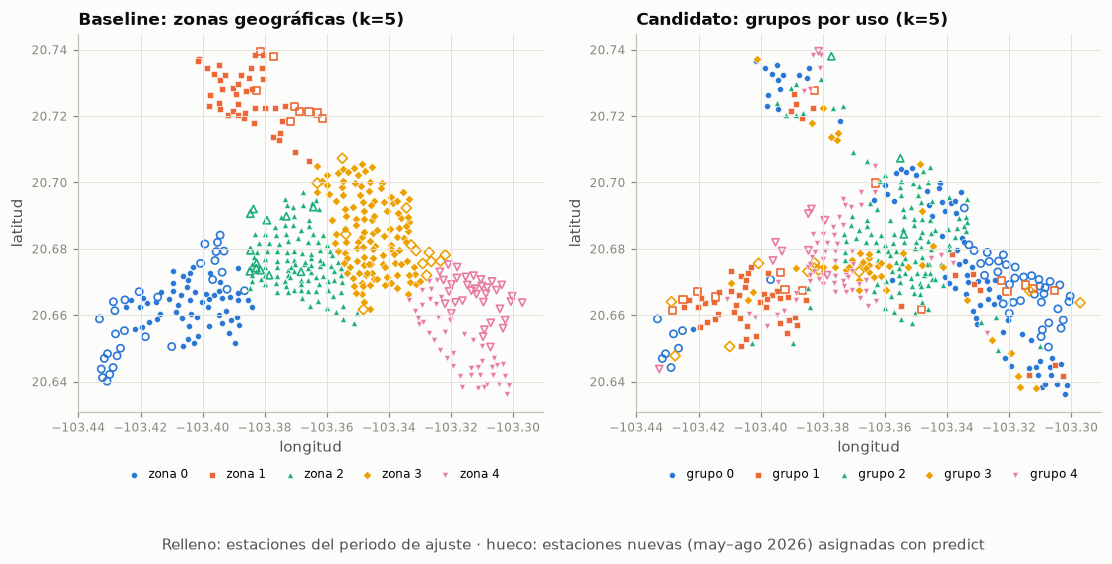

In [109]:
def mapa_grupos(ax, indices, etiquetas, titulo, huecos=None, etiquetas_huecos=None, prefijo="zona"):
    # Estaciones en el mapa: color + forma por grupo (la forma evita depender solo del color);
    # las estaciones nuevas se dibujan huecas
    lon, lat = nom.loc[indices, "longitude"], nom.loc[indices, "latitude"]
    for g in sorted(set(etiquetas)):
        m = np.asarray(etiquetas) == g
        ax.scatter(lon[m], lat[m], s=16, color=SERIES[g], marker=MARCADORES[g], label=f"{prefijo} {g}",
                   edgecolor=SUPERFICIE, linewidth=0.4)
        if huecos is not None:
            mh = np.asarray(etiquetas_huecos) == g
            ax.scatter(nom.loc[huecos[mh], "longitude"], nom.loc[huecos[mh], "latitude"], s=22,
                       facecolor="none", edgecolor=SERIES[g], marker=MARCADORES[g], linewidth=1.1)
    ax.set_aspect(1 / np.cos(np.radians(LAT_REF)))
    ax.set_title(titulo); ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
    ax.tick_params(labelsize=8)


# Estaciones nuevas: el baseline las asigna por ubicación; el candidato, si ya tienen ≥ 60 días de datos
nuevas_ok = nuevas[nuevas.isin(nom.index)]
nuevas_uso = ev.index.intersection(nuevas)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6))
mapa_grupos(a1, aj.index, et_base, f"Baseline: zonas geográficas (k={K_BASELINE})",
            nuevas_ok, baselines[K_BASELINE].predict(a_km(nuevas_ok)))
mapa_grupos(a2, aj.index, et_cand_aj, f"Candidato: grupos por uso (k={K_BASELINE})",
            nuevas_uso, et_cand_ev[nuevas_uso], prefijo="grupo")
for ax in (a1, a2):
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, fontsize=8, handletextpad=0.2, columnspacing=0.9)
fig.text(0.5, 0.0, "Relleno: estaciones del periodo de entrenamiento · hueco: estaciones nuevas (may–ago 2026) asignadas con predict",
         ha="center", color=TINTA2)
guardar(fig, "p3_mapa_baseline_vs_candidato.png")

In [110]:
# ¿Cómo se usan las estaciones de cada zona (baseline) y de cada grupo (candidato)?
resumen = lambda et, nombre: (aj.assign(**{nombre: et}).groupby(nombre)
                      .agg(estaciones=("trips_day", "size"), viajes_dia=("trips_day", "median"),
                           **{v: (v, "mean") for v in VARS if v != "log_trips_day"},
                           lat=("lat", "mean"), lon=("lon", "mean"),
                           pct_GDL=("municipio", lambda m: (m == "GDL").mean()),
                           pct_ZPN=("municipio", lambda m: (m == "ZPN").mean()),
                           pct_TLQ=("municipio", lambda m: (m == "TLQ").mean())))
aj = aj.join(nom[["municipio"]]).assign(lat=nom.loc[aj.index, "latitude"], lon=nom.loc[aj.index, "longitude"])
print(f"Perfil medio por ZONA geográfica (baseline k={K_BASELINE}):")
display(resumen(et_base, "zona").style.format(precision=2).format("{:.3f}", subset=["lat", "lon"]))
print(f"Perfil medio por GRUPO de uso (candidato k={K_BASELINE}):")
display(resumen(et_cand_aj, "grupo").style.format(precision=2).format("{:.3f}", subset=["lat", "lon"]))
print("Grupos de uso dentro de cada zona geográfica (estaciones):")
display(pd.crosstab(et_base.rename("zona"), et_cand_aj.rename("grupo de uso")))
print("Estaciones nuevas por zona (baseline):",
      pd.Series(baselines[K_BASELINE].predict(a_km(nuevas_ok))).value_counts().sort_index().to_dict(),
      "| por grupo de uso (candidato, solo con ≥ 60 días):", et_cand_ev[nuevas_uso].value_counts().sort_index().to_dict())

Perfil medio por ZONA geográfica (baseline k=5):


,estaciones,viajes_dia,weekend_share,net_am,net_pm,dep_pm,dep_night,arr_night,lat,lon,pct_GDL,pct_ZPN,pct_TLQ
zona,,,,,,,,,,,,,
0,58,9.28,0.22,-0.04,-0.29,0.38,0.08,0.08,20.663,-103.403,0.40,0.60,0.00
1,41,14.85,0.18,-0.13,0.00,0.30,0.09,0.11,20.726,-103.386,0.05,0.95,0.00
2,107,40.76,0.20,0.12,-0.18,0.34,0.09,0.08,20.676,-103.369,1.00,0.00,0.00
3,120,30.45,0.20,-0.15,0.20,0.26,0.08,0.11,20.684,-103.346,1.00,0.00,0.00
4,44,12.08,0.24,-0.35,0.12,0.27,0.09,0.12,20.651,-103.317,0.66,0.00,0.34


Perfil medio por GRUPO de uso (candidato k=5):


,estaciones,viajes_dia,weekend_share,net_am,net_pm,dep_pm,dep_night,arr_night,lat,lon,pct_GDL,pct_ZPN,pct_TLQ
grupo,,,,,,,,,,,,,
0,79,12.12,0.22,-0.49,0.23,0.24,0.08,0.14,20.681,-103.343,0.68,0.19,0.13
1,55,8.46,0.23,-0.09,-0.25,0.36,0.07,0.08,20.668,-103.390,0.40,0.56,0.04
2,126,39.20,0.19,-0.08,0.09,0.28,0.07,0.09,20.683,-103.355,0.92,0.08,0.00
3,44,43.64,0.25,0.12,-0.06,0.34,0.13,0.10,20.678,-103.363,0.73,0.20,0.07
4,66,27.93,0.17,0.32,-0.30,0.38,0.08,0.06,20.680,-103.376,0.86,0.14,0.00


Grupos de uso dentro de cada zona geográfica (estaciones):


grupo de uso,0,1,2,3,4
zona,,,,,
0,1,41,3,4,9
1,14,5,11,6,5
2,2,1,37,21,46
3,33,4,71,7,5
4,29,4,4,6,1


Estaciones nuevas por zona (baseline): {0: 30, 1: 9, 2: 12, 3: 13, 4: 35} | por grupo de uso (candidato, solo con ≥ 60 días): {0: 45, 1: 15, 2: 3, 3: 11, 4: 10}


**Lectura de los resultados**

- **El candidato agrupa mucho mejor que el baseline.** En el espacio de uso, su silhouette es 0.189 contra 0.049 en entrenamiento y 0.158 contra 0.025 en evaluación. Davies-Bouldin baja de 2.72 a 1.51 y Calinski-Harabasz sube de 32 a 81. El baseline queda cerca de cero con k = 4, 5 y 6 (0.067, 0.049 y 0.021): **ninguna división por cercanía agrupa estaciones que se usen igual**. Lo confirma la poca coincidencia entre zonas y grupos de uso (ARI = 0.225): estaciones vecinas pueden tener funciones muy distintas.
- **Los grupos se sostienen fuera del periodo de entrenamiento.** La silhouette baja poco en evaluación (0.189 → 0.158), y eso que ese periodo incluye 84 estaciones nuevas y otra estacionalidad. La estabilidad es ARI = 0.60. El valor absoluto es moderado, como es típico en datos de comportamiento continuo: los grupos son gradientes, no islas separadas. Elegir k y probar otros algoritmos queda para la siguiente entrega.
- **Qué es cada grupo:** se describe en la ficha de la sección 8.1.
- **La expansión de 2026 fue hacia zonas residenciales.** De las 84 estaciones nuevas con 60 días de datos, 45 (54%) se comportan como residenciales (grupo 0). El baseline ubica a la mayoría de las 99 en las zonas del poniente (30) y del sureste (35). Para Planeación, esto significa que esas estaciones se vaciarán por la mañana y que hace falta coordinarlas con el rebalanceo (P2).

### 7.1 Ficha de cada grupo

Para reconocer de qué tipo de estación se trata cada grupo, se combinan cuatro aspectos:

1. **Qué lo distingue:** el promedio de cada variable en desviaciones estándar respecto a la estación promedio.
2. **Firma horaria:** cómo se reparten las salidas y llegadas del día hábil.
3. **Estaciones representativas:** las más cercanas al centro del grupo.
4. **Contexto y ubicación:** distancia al centro, capacidad, municipio y mapa.

Las etiquetas del final son una interpretación de estos datos. Conviene validarlas con quien conozca la ciudad.

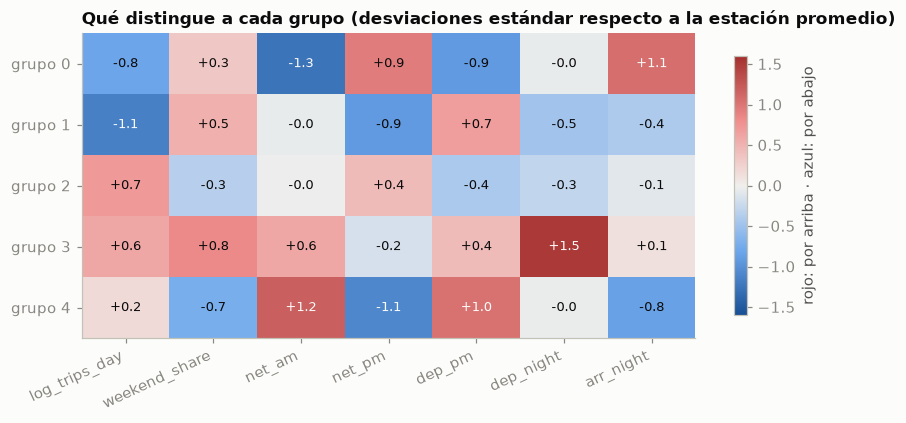

In [111]:
# 1) Qué distingue a cada grupo: media de cada variable estandarizada (0 = estación promedio del periodo de entrenamiento)
z = pd.DataFrame(X_aj, index=aj.index, columns=VARS).groupby(et_cand_aj.values).mean()
lim = np.ceil(np.abs(z.values).max() * 10) / 10
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(z.values, cmap=DIVERGENTE, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(VARS)), VARS, rotation=25, ha="right")
ax.set_yticks(range(len(z)), [f"grupo {g}" for g in z.index]); ax.grid(False)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        v = z.iat[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8.5,
                color=SUPERFICIE if abs(v) >= 0.6 * lim else TINTA)
ax.set_title("Qué distingue a cada grupo (desviaciones estándar respecto a la estación promedio)")
fig.colorbar(im, ax=ax, shrink=0.85, label="rojo: por arriba · azul: por abajo")
guardar(fig, "p3_ficha_rasgos_grupos.png")

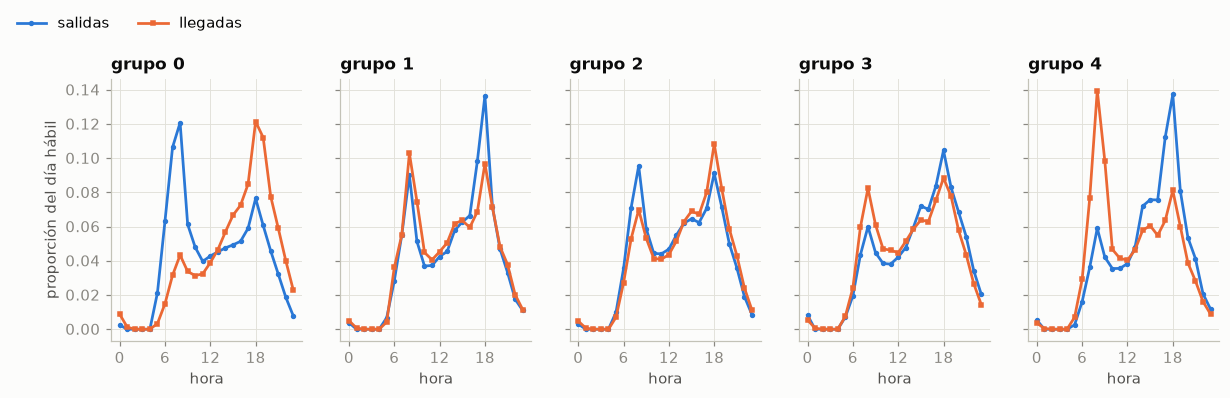

,hora_pico_salidas,hora_pico_llegadas,salidas_6a9h,llegadas_6a9h,salidas_17a20h,llegadas_17a20h
grupo,,,,,,
0,8,18,0.35,0.12,0.24,0.40
1,18,8,0.23,0.27,0.35,0.29
2,8,18,0.26,0.20,0.28,0.33
3,18,18,0.17,0.23,0.34,0.30
4,18,8,0.15,0.34,0.38,0.24


In [112]:
# 2) Firma horaria de cada grupo: proporción de las salidas y llegadas del día hábil en cada hora
grupo_de = pd.Series(et_cand_aj.values, index=aj.index)
firma = lambda m: (lambda t: t.div(t.sum(axis=1), axis=0))(m.loc[aj.index].groupby(grupo_de).sum())
sal_g, lle_g = firma(sal_h), firma(lle_h)
fig, axes = plt.subplots(1, K_BASELINE, figsize=(13, 3.1), sharey=True)
for g, ax in enumerate(axes):
    ax.plot(range(24), sal_g.loc[g], color=SERIES[0], marker="o", ms=2.5, lw=1.8, label="salidas")
    ax.plot(range(24), lle_g.loc[g], color=SERIES[1], marker="s", ms=2.5, lw=1.8, label="llegadas")
    ax.set_title(f"grupo {g}"); ax.set_xticks([0, 6, 12, 18]); ax.set_xlabel("hora")
axes[0].set_ylabel("proporción del día hábil")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.05, 1.1), ncol=2)
guardar(fig, "p3_ficha_firma_horaria.png")
picos = pd.DataFrame({"hora_pico_salidas": sal_g.idxmax(axis=1), "hora_pico_llegadas": lle_g.idxmax(axis=1),
                      "salidas_6a9h": sal_g[FRANJAS["am"]].sum(axis=1), "llegadas_6a9h": lle_g[FRANJAS["am"]].sum(axis=1),
                      "salidas_17a20h": sal_g[FRANJAS["pm"]].sum(axis=1), "llegadas_17a20h": lle_g[FRANJAS["pm"]].sum(axis=1)})
display(picos.rename_axis("grupo").style.format("{:.2f}", subset=picos.columns[2:]))

In [113]:
# 3) Estaciones representativas: las 5 más cercanas al centro de su grupo (en el espacio de uso estandarizado)
filas = []
for g in range(K_BASELINE):
    m = et_cand_aj.values == g
    dist = np.linalg.norm(X_aj[m] - X_aj[m].mean(axis=0), axis=1)
    for est in aj.index[m][np.argsort(dist)[:5]]:
        filas.append({"grupo": g, "estacion": est, "nombre": nom.loc[est, "name"],
                      "viajes_dia": aj.loc[est, "trips_day"], "net_am": aj.loc[est, "net_am"],
                      "net_pm": aj.loc[est, "net_pm"], "weekend_share": aj.loc[est, "weekend_share"]})
representativas = pd.DataFrame(filas)
display(representativas.style.format(precision=2).hide(axis="index"))

grupo,estacion,nombre,viajes_dia,net_am,net_pm,weekend_share
0,389,(ZPN-014) Av. D / San Jorge,12.70,-0.29,0.18,0.21
0,366,(GDL-271) Román Morales / Álvaro Obregón,9.03,-0.53,0.21,0.23
0,322,(GDL-225) C. Gral Carlos Fuero/Av. Revolución,14.92,-0.67,0.13,0.21
0,270,(GDL-197) Av. Río Nilo / Av. Revolución,13.02,-0.36,0.16,0.21
0,95,(ZPN-005) C. Del Corral / C. Anáhuac,5.72,-0.49,0.07,0.22
1,241,(GDL-174) C. Juan de Zumárraga / Av. Tepeyac,10.69,-0.03,-0.33,0.24
1,126,(ZPN-032) Calz Lázaro Cárdenas / Av San Fco,9.28,-0.12,-0.25,0.23
1,130,(ZPN-036) C. Niño Obrero /C José María Robles,12.87,-0.07,-0.20,0.25
1,214,(GDL-147) Calz. Lázaro Cárdenas/Av. Guadalupe,9.95,-0.19,-0.35,0.21
1,141,(ZPN-047) Av. Tizoc / Av. López Mateos,9.28,0.01,-0.15,0.18


,estaciones,viajes_dia_mediana,dist_centro_km_mediana,capacidad_mediana,pct_GDL,pct_ZPN,pct_TLQ,nuevas_asignadas
grupo,,,,,,,,
0,79,12.1,2.8,15.0,68%,19%,13%,45
1,55,8.5,6.1,15.0,40%,56%,4%,15
2,126,39.2,1.7,15.0,92%,8%,0%,3
3,44,43.6,2.4,17.0,73%,20%,7%,11
4,66,27.9,3.3,15.0,86%,14%,0%,10


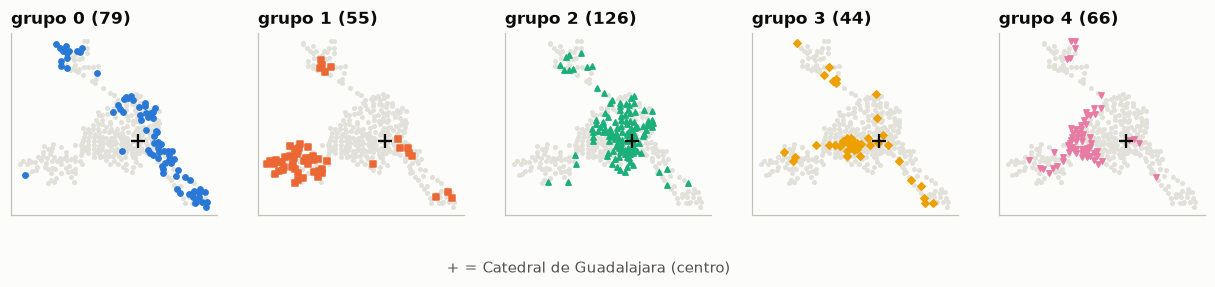

In [114]:
# 4) Contexto y ubicación de cada grupo
dist_centro = np.hypot((nom.latitude - CENTRO_GDL[0]) * 111.32,
                       (nom.longitude - CENTRO_GDL[1]) * 111.32 * np.cos(np.radians(LAT_REF)))
contexto = (aj.assign(grupo=grupo_de, dist_centro_km=dist_centro.loc[aj.index], capacidad=nom.loc[aj.index, "dpcapacity"])
            .groupby("grupo").agg(estaciones=("trips_day", "size"), viajes_dia_mediana=("trips_day", "median"),
                                  dist_centro_km_mediana=("dist_centro_km", "median"),
                                  capacidad_mediana=("capacidad", "median"),
                                  pct_GDL=("municipio", lambda m: (m == "GDL").mean()),
                                  pct_ZPN=("municipio", lambda m: (m == "ZPN").mean()),
                                  pct_TLQ=("municipio", lambda m: (m == "TLQ").mean())))
contexto["nuevas_asignadas"] = et_cand_ev[nuevas_uso].value_counts().reindex(contexto.index, fill_value=0)
display(contexto.style.format(precision=1).format("{:.0%}", subset=["pct_GDL", "pct_ZPN", "pct_TLQ"]))

# Un mapa por grupo: el grupo resaltado sobre todas las estaciones en gris
fig, axes = plt.subplots(1, K_BASELINE, figsize=(14, 3.6), sharex=True, sharey=True)
for g, ax in enumerate(axes):
    ax.scatter(nom.loc[aj.index, "longitude"], nom.loc[aj.index, "latitude"], s=5, color=REJILLA)
    est = aj.index[et_cand_aj.values == g]
    ax.scatter(nom.loc[est, "longitude"], nom.loc[est, "latitude"], s=12, color=SERIES[g], marker=MARCADORES[g])
    ax.plot(CENTRO_GDL[1], CENTRO_GDL[0], marker="+", color=TINTA, ms=9, mew=1.5)
    ax.set_aspect(1 / np.cos(np.radians(LAT_REF))); ax.set_title(f"grupo {g} ({len(est)})")
    ax.set_xticks([]); ax.set_yticks([])
fig.text(0.5, 0.12, "+ = Catedral de Guadalajara (centro)", ha="center", color=TINTA2)
guardar(fig, "p3_ficha_mapas_grupos.png")

**Ficha de cada grupo**

- **Grupo 0 (79), residencial:** se vacía en la mañana y se llena en la tarde y la noche. Está en un arco alrededor del centro (oriente de Guadalajara hacia Tlaquepaque y norte de Zapopan). Necesita rebalanceo temprano, y es el tipo de 45 de las 84 estaciones nuevas evaluables.
- **Grupo 1 (55), destino periférico de baja intensidad:** poco uso; recibe en la mañana y despide en la tarde. Está sobre todo al surponiente, en Zapopan. Conviene revisar ubicación o conexión.
- **Grupo 2 (126), centro mixto:** mucho uso con flujos equilibrados, alrededor de la Catedral. Conviene ampliar anclajes más que rebalancear.
- **Grupo 3 (44), ocio y vida nocturna:** mucho uso en la noche y en fin de semana, a lo largo de los ejes del centro hacia el poniente. Requiere operación nocturna.
- **Grupo 4 (66), polo de empleo y estudio:** se llena en la mañana y se vacía en la tarde, al poniente inmediato del centro. Puede quedarse sin anclajes; se relaciona con P2.

**Otros hallazgos:**

- La capacidad casi no cambia entre grupos (15 anclajes de mediana), aunque su uso es muy distinto.
- Los nombres de los grupos son una interpretación y conviene validarlos con conocimiento local.

---
## 8. Registro en MLflow (Pasos 6 y 7)

Se registran las tres corridas del baseline (k = 4, 5 y 6). Así queda la captura de comparación entre runs. Cada run lleva:

- **Parámetros:** fechas de entrenamiento y evaluación, "data_version", semilla, modelo, k, "n_init", variables de entrada y de evaluación, umbrales de limpieza y elegibilidad.
- **Métricas** con prefijo del conjunto ("train_*", "test_*").
- **Etiquetas:** "equipo", "pregunta", "tipo", "git_commit", "autor" y "origen".
- **Artefactos:** mapa, asignación de estaciones, perfil de zonas y bitácora de limpieza. Ninguno contiene datos personales.

El backend es "mlflow.db" (SQLite) y los artefactos van a "mlartifacts/", ambos en la raíz del repositorio y **ambos deben estar en ".gitignore"**. La celda siguiente lo verifica.


In [115]:
def git(*args):
    return subprocess.run(["git", *args], cwd=PROJ_ROOT, capture_output=True, text=True)


GIT_COMMIT = git("rev-parse", "HEAD").stdout.strip() or "sin-git"
GIT_SUCIO = bool(git("status", "--porcelain").stdout.strip())
print(f"Commit: {GIT_COMMIT[:7]} | cambios sin commit: {'sí' if GIT_SUCIO else 'no'}")
for ruta in ["mlflow.db", "mlartifacts/", "mlruns/", "data/"]:
    ignorado = git("check-ignore", "-q", ruta).returncode == 0
    print(f"  {ruta:13s} {'ignorado por Git' if ignorado else '⚠ NO está en .gitignore: agrégalo antes de hacer commit'}")

mlflow.set_tracking_uri(f"sqlite:///{(PROJ_ROOT / 'mlflow.db').as_posix()}")
if mlflow.get_experiment_by_name(EXPERIMENTO) is None:
    mlflow.create_experiment(EXPERIMENTO, artifact_location=(PROJ_ROOT / "mlartifacts").as_uri())
mlflow.set_experiment(EXPERIMENTO)
print("Experimento:", EXPERIMENTO)

Commit: 537a4d8 | cambios sin commit: sí
  mlflow.db     ⚠ NO está en .gitignore: agrégalo antes de hacer commit
  mlartifacts/  ignorado por Git
  mlruns/       ignorado por Git
  data/         ignorado por Git
Experimento: mibici-equipo29


In [116]:
def registrar_baseline(k):
    # Registra un run del baseline geográfico con parámetros, métricas, etiquetas y artefactos
    km, m = baselines[k], resultados[f"baseline geo k={k}"]
    et_aj = pd.Series(km.labels_, index=aj.index)
    with mlflow.start_run(run_name=f"p3-baseline-kmeans-geo-k{k}") as run:
        mlflow.set_tags({"equipo": EQUIPO, "pregunta": "P3", "tipo": "baseline", "autor": "fbr",
                         "git_commit": GIT_COMMIT, "git_cambios_sin_commit": str(GIT_SUCIO),
                         "origen": "notebooks/1.0-fbr-p3-exploracion-clustering.ipynb"})
        mlflow.log_params({
            "fecha_inicio_entrenamiento": AJUSTE[0], "fecha_fin_entrenamiento": AJUSTE[1],
            "fecha_inicio_evaluacion": EVALUACION[0], "fecha_fin_evaluacion": EVALUACION[1],
            "data_version": DATA_VERSION, "seed": SEED, "modelo": "KMeans", "k": k, "n_init": 20,
            "entrada_modelo": "x_km,y_km", "lat_ref": LAT_REF, "variables_evaluacion": ",".join(VARS),
            "min_dias_activos": MIN_DIAS_ACTIVOS, "duracion_min_seg": DURACION_MIN_SEG,
            "n_estaciones_entrenamiento": len(aj), "n_estaciones_evaluacion": len(ev)})
        mlflow.log_metrics(m)
        with tempfile.TemporaryDirectory() as tmp:
            tmp = Path(tmp)
            fig, ax = plt.subplots(figsize=(6.5, 6.5))
            mapa_grupos(ax, aj.index, et_aj, f"P3 baseline: zonas geográficas (k={k})",
                        nuevas_ok, km.predict(a_km(nuevas_ok)))
            ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=k, fontsize=8)
            fig.savefig(tmp / f"p3_mapa_baseline_k{k}.png"); plt.close(fig)
            asignacion = pd.concat([
                nom.loc[aj.index, ["name", "municipio", "latitude", "longitude"]].assign(zona=et_aj, periodo="entrenamiento"),
                nom.loc[nuevas_ok, ["name", "municipio", "latitude", "longitude"]].assign(
                    zona=km.predict(a_km(nuevas_ok)), periodo="nueva (predict)")])
            asignacion.rename_axis("estacion").to_csv(tmp / "asignacion_estaciones.csv")
            aj.assign(zona=et_aj).groupby("zona")[["trips_day"] + VARS].mean().round(4).to_csv(tmp / "perfil_uso_por_zona.csv")
            bitacora.to_csv(tmp / "bitacora_limpieza.csv", index=False)
            mlflow.log_artifacts(str(tmp))
        return run.info.run_id


ids = {k: registrar_baseline(k) for k in K_COMPARACION}
runs = mlflow.search_runs(experiment_names=[EXPERIMENTO], filter_string="tags.pregunta = 'P3'",
                          order_by=["attributes.start_time DESC"]).head(len(ids))
cols = ["tags.mlflow.runName", "params.k", "params.data_version", "metrics.train_silhouette_uso",
        "metrics.test_silhouette_uso", "metrics.train_davies_bouldin_uso", "tags.git_commit"]
display(runs[cols].assign(**{"tags.git_commit": runs["tags.git_commit"].str[:7]}).style.format(precision=3).hide(axis="index"))

tags.mlflow.runName,params.k,params.data_version,metrics.train_silhouette_uso,metrics.test_silhouette_uso,metrics.train_davies_bouldin_uso,tags.git_commit
p3-baseline-kmeans-geo-k6,6,b82961c841c7,0.021,-0.003,3.944,537a4d8
p3-baseline-kmeans-geo-k5,5,b82961c841c7,0.049,0.025,2.722,537a4d8
p3-baseline-kmeans-geo-k4,4,b82961c841c7,0.067,0.060,2.973,537a4d8


**Capturas para el PDF (Paso 7).** Desde la raíz del repositorio, con el entorno activado:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

Luego, en <http://127.0.0.1:5000>, tomar cuatro capturas:

1. La lista de runs del experimento "mibici-equipo29".
2. El detalle de "p3-baseline-kmeans-geo-k5": parámetros, métricas y etiquetas.
3. El artefacto "p3_mapa_baseline_k5.png".
4. La comparación de los tres runs: seleccionarlos y presionar **Compare**.

---
## 9. Reproducibilidad y código reutilizable

In [117]:
import importlib.metadata as md_
versiones = {p: md_.version(p) for p in ["pandas", "numpy", "scikit-learn", "matplotlib", "mlflow"]}
print("Python", sys.version.split()[0], "|", " · ".join(f"{k} {v}" for k, v in versiones.items()))
print("data_version:", DATA_VERSION, "| commit:", GIT_COMMIT[:7], "| semilla:", SEED)
print("Figuras generadas en reports/figures/:", sorted(p.name for p in FIGURES_DIR.glob("p3_*.png")))

Python 3.14.7 | pandas 3.0.6 · numpy 2.5.3 · scikit-learn 1.9.1 · matplotlib 3.11.2 · mlflow 3.16.1
data_version: b82961c841c7 | commit: 537a4d8 | semilla: 42
Figuras generadas en reports/figures/: ['p3_correlacion_candidatas.png', 'p3_curva_horaria_sistema.png', 'p3_error_estandar_vs_dias.png', 'p3_ficha_firma_horaria.png', 'p3_ficha_mapas_grupos.png', 'p3_ficha_rasgos_grupos.png', 'p3_flujo_neto_ejemplos.png', 'p3_heatmap_perfil_horario.png', 'p3_intensidad_uso.png', 'p3_mapa_baseline_vs_candidato.png', 'p3_viajes_y_estaciones_por_mes.png']
